# Step 11: what drives model C? (SHAP)
Model C = **multiplier x scale**, with scale = max(past spend, 50). The trees learn only the multiplier (Tweedie, log link), so SHAP explains `log(multiplier)`: +0.1 means the multiplier is about 10% higher than for the average customer. Fitted and explained on train; the test set is not needed here.

In [1]:
import sys, warnings; sys.path.insert(0, '../src'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from step11_shap import fit_and_explain, main
X, y, model, sv = fit_and_explain()
main()

customers 4242; average multiplier 0.355; spread (5th to 95th pct) 0.308 to 0.399

Global importance on the multiplier:
              mean |SHAP|  share  cum share  direction (corr with SHAP)
IPI                 0.046  0.334      0.334                      -0.737
Recency             0.043  0.306      0.640                      -0.916
OverdueRatio        0.030  0.215      0.855                      -0.487
Monetary            0.011  0.076      0.931                      -0.260
Frequency           0.010  0.069      1.000                      -0.374

Average multiplier by quintile of each feature:
   Recency  Frequency  Monetary
0    0.377      0.365     0.361
1    0.372      0.357     0.354
2    0.358      0.338     0.347
3    0.337      0.345     0.349
4    0.329      0.369     0.363

real multiplier (future / scale) by the same quintiles:
   Recency  Frequency  Monetary
0    0.480      0.408     0.525
1    0.400      0.462     0.415
2    0.438      0.352     0.353
3    0.344      0.376 

## Global picture: which features move the multiplier

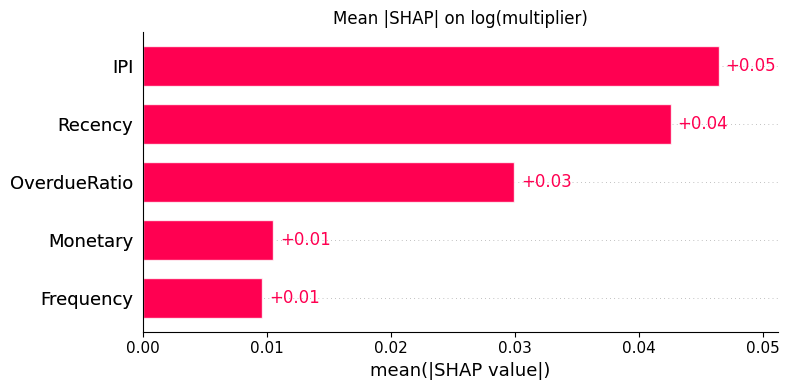

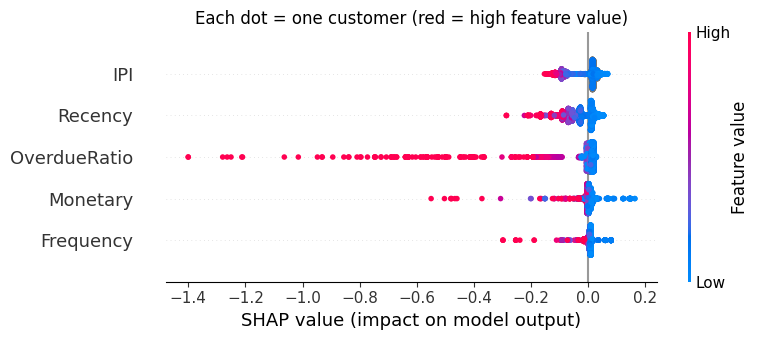

In [2]:
shap.plots.bar(sv, show=False); plt.title('Mean |SHAP| on log(multiplier)'); plt.tight_layout(); plt.show()
shap.plots.beeswarm(sv, show=False); plt.title('Each dot = one customer (red = high feature value)'); plt.tight_layout(); plt.show()

## Local picture: three customers (biggest actual spender, a typical customer, a lapsed one)

biggest actual spender: past spend 245,028, multiplier 0.390, prediction 95,456, actual 110,668


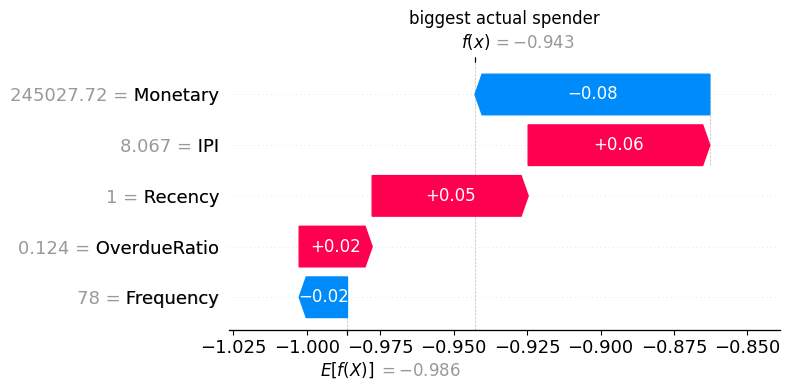

typical (median prediction): past spend 629, multiplier 0.370, prediction 233, actual 0


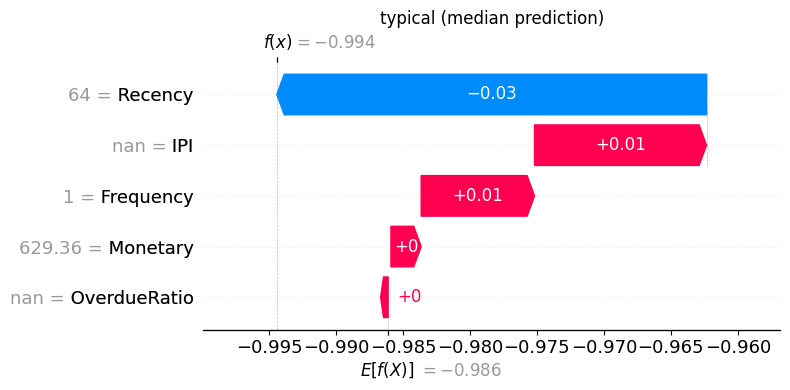

lapsed (longest recency): past spend 130, multiplier 0.349, prediction 45, actual 969


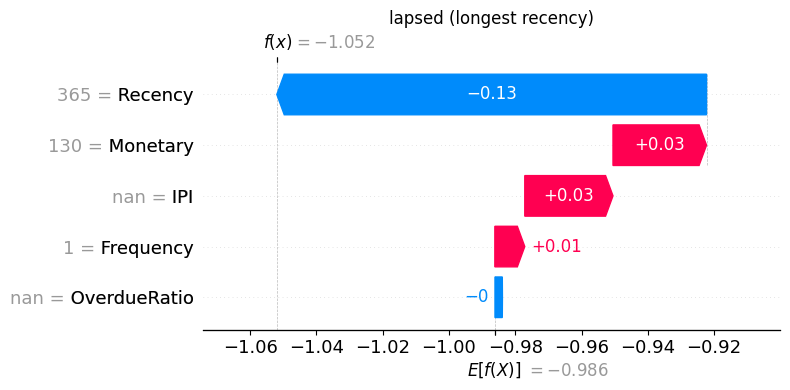

In [3]:
scale = X['Monetary'].clip(lower=50).to_numpy(); pred = model.predict(X)
picks = {'biggest actual spender': int(np.argmax(y.to_numpy())),
         'typical (median prediction)': int(np.argsort(pred)[len(pred)//2]),
         'lapsed (longest recency)': int(np.argmax(X['Recency'].to_numpy()))}
for name, i in picks.items():
    print(f"{name}: past spend {X['Monetary'].iloc[i]:,.0f}, multiplier {np.exp(sv.values[i].sum()+sv.base_values[i]):.3f}, prediction {pred[i]:,.0f}, actual {y.iloc[i]:,.0f}")
    shap.plots.waterfall(sv[i], show=False); plt.title(name); plt.tight_layout(); plt.show()

## What we learned
- **Past spend does almost all the work**: the prediction ranks customers almost exactly like Monetary (rank correlation 0.993). The trees only nudge the multiplier within about 0.31 to 0.40 (average 0.355), i.e. roughly +/-12%.
- **What does the nudging:** purchase interval (IPI, 33%), Recency (31%) and OverdueRatio (22%) = 86% of the SHAP total. Frequency and Monetary together only 14%.
- **Directions make sense:** shorter gap since the last purchase (low Recency) and shorter interval between purchases raise the multiplier; being very overdue lowers it.
- **The old goal "top 5 features cover >= 70%" is meaningless here**: we have exactly 5 features, so it is 100% by construction. The top 3 cover 86%.
- **Caution:** SHAP shows what the model *uses*, not what *helps*. IPI is the biggest nudge, yet step 8 and the fresh-seed check could not prove it improves accuracy. The nudges are real but small.